<a href="https://colab.research.google.com/github/Devesh07-OGDemiGOD/Quantum-Walk-Simulation/blob/Quantum-Collab/Task2_Roll_Number_Quantum_Circuit_2025BCY0042.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 2: Personalized 12-Qubit Quantum Circuit Design

**Roll number:** `2025BCY0042`

This notebook converts the roll number into a 12-bit string, builds the required 12-qubit circuit, displays the circuit, and visualizes measurement results with a histogram.

**Rule used:** the leftmost bit of the 12-bit string is assigned to qubit `q0`, the next bit to `q1`, and so on. Qiskit displays measured bit strings in the reverse qubit order (`q11 ... q0`).

In [1]:
%pip -q install qiskit qiskit-aer matplotlib pylatexenc

In [2]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

# Roll-number encoding
roll_number = "2025BCY0042"
year = int(roll_number[:4])
last_four_digits = int(roll_number[-4:])
encoded_number = year + last_four_digits

# Keep exactly the last 12 bits (and pad with leading zeroes if needed)
binary_string = format(encoded_number % (2**12), "012b")
last_digit = int(roll_number[-1])

print("Roll number:", roll_number)
print("Year:", year)
print("Last four digits as a number:", last_four_digits)
print(f"Encoded number: {year} + {last_four_digits} = {encoded_number}")
print("12-bit binary string:", binary_string)
print("Last roll-number digit:", last_digit)
print("Last digit is even:", last_digit % 2 == 0)

Roll number: 2025BCY0042
Year: 2025
Last four digits as a number: 42
Encoded number: 2025 + 42 = 2067
12-bit binary string: 100000010011
Last roll-number digit: 2
Last digit is even: True


## Build the 12-qubit circuit

- Initialize each qubit to match its assigned bit (`0` stays \(|0\rangle\), `1` is changed to \(|1\rangle\) using an X gate).
- Apply H to each qubit whose original bit is `1`.
- Apply the valid CNOT connections `q2 → q3`, `q5 → q6`, and `q8 → q9` (these are qubits 3→4, 6→7, and 9→10 in 1-based numbering).
- Since the last digit of the roll number is even, apply X to the last qubit (`q11`).
- Measure all qubits.

Qubits initialized to |1> from the binary string: [0, 7, 10, 11]
CNOT pairs (zero-based indices): [(2, 3), (5, 6), (8, 9)]
Last-qubit gate: X


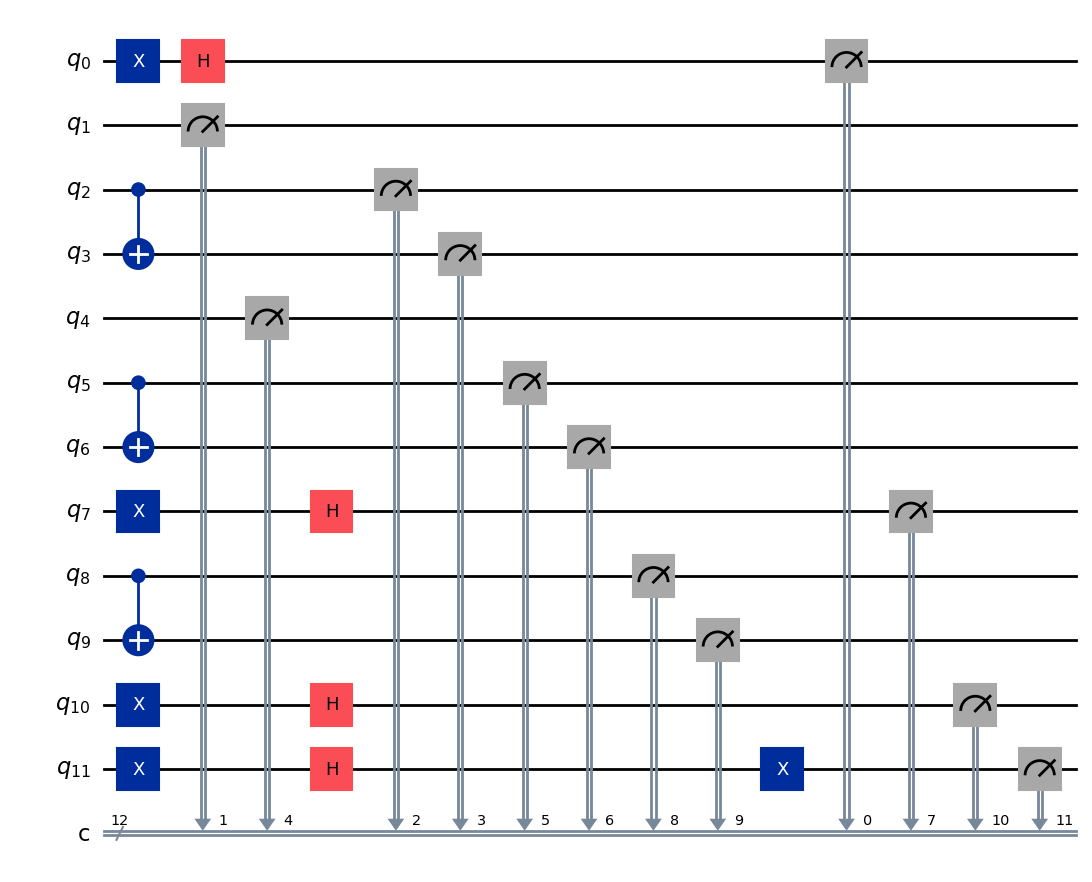

In [3]:
n_qubits = 12
qc = QuantumCircuit(n_qubits, n_qubits)

# Step 1: encode the binary string into the initial computational-basis state.
# The leftmost character is mapped to q0, then q1, ... q11.
one_qubits = []
for qubit, bit in enumerate(binary_string):
    if bit == "1":
        qc.x(qubit)
        one_qubits.append(qubit)

# Step 2: Hadamard gates on qubits whose original encoded bit was 1.
for qubit in one_qubits:
    qc.h(qubit)

# Step 3: CNOT gates. The 12th qubit has no next qubit, so no CNOT can
# be made from q11 to q12; q12 does not exist in a 12-qubit circuit.
cnot_pairs = [(2, 3), (5, 6), (8, 9)]
for control, target in cnot_pairs:
    qc.cx(control, target)

# Step 4: last roll-number digit is even -> apply X to the last qubit.
if last_digit % 2 == 0:
    qc.x(11)
else:
    qc.z(11)

# Step 5: measurement
qc.measure(range(n_qubits), range(n_qubits))

print("Qubits initialized to |1> from the binary string:", one_qubits)
print("CNOT pairs (zero-based indices):", cnot_pairs)
print("Last-qubit gate:", "X" if last_digit % 2 == 0 else "Z")
display(qc.draw("mpl", fold=-1))

## Simulate and visualize the measurement results

The simulator runs the circuit many times (shots). The histogram shows the measured 12-bit outcomes and how often each one appeared.

In [4]:
simulator = AerSimulator()
compiled_qc = transpile(qc, simulator)
result = simulator.run(compiled_qc, shots=2048).result()
counts = result.get_counts()

print("Measurement counts:")
print(counts)

plot_histogram(counts, title="Task 2: Measurement Results (2048 shots)")
plt.show()

Measurement counts:
{'000000000001': 120, '000010000000': 131, '010010000000': 118, '010010000001': 133, '110000000001': 135, '010000000001': 121, '100010000000': 140, '100010000001': 147, '100000000001': 144, '110010000001': 141, '110000000000': 133, '000000000000': 105, '010000000000': 134, '000010000001': 117, '110010000000': 117, '100000000000': 112}


## Short inference (submission answer)

The Hadamard gates put the qubits whose encoded bits were `1` into superposition, so their measurement outcomes can vary. The CNOT gates are placed between qubits 3→4, 6→7, and 9→10 as required; for this roll number, the control qubits (q2, q5, and q8) remain in \(|0\rangle\), so these CNOTs do not actually create entanglement in this particular circuit. The histogram should therefore show variation mainly in the qubits that received Hadamard gates, while the other qubits remain fixed apart from the final X gate on q11.

**Note:** Qiskit prints classical measurement strings in `q11 ... q0` order, which is the reverse of the bit-to-qubit mapping used above.